# Netflix Data Analysis

This project analyzes Netflix content using Python, Pandas, and Matplotlib to explore content distribution, producing countries, release trends, ratings, and top directors.

## 1. Load the Dataset

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Dataset Overview

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## 3. Missing Values Analysis
This step helps identify columns with missing data and gives a first impression of data quality.

In [29]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


## 4. Content Type Distribution
This chart compares the number of Movies and TV Shows in the Netflix dataset.

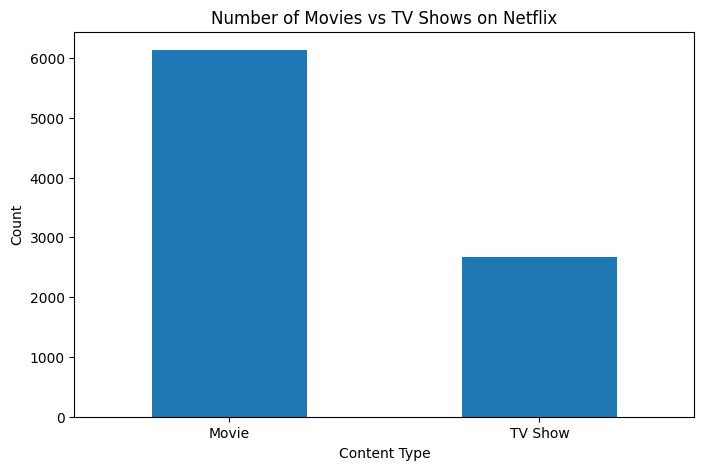

In [30]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(8, 5))
type_counts.plot(kind="bar")
plt.title("Number of Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Insight
Movies appear more frequently than TV Shows in the dataset.

## 5. Top 10 Producing Countries
Some rows include multiple countries, so the values are split before analysis.

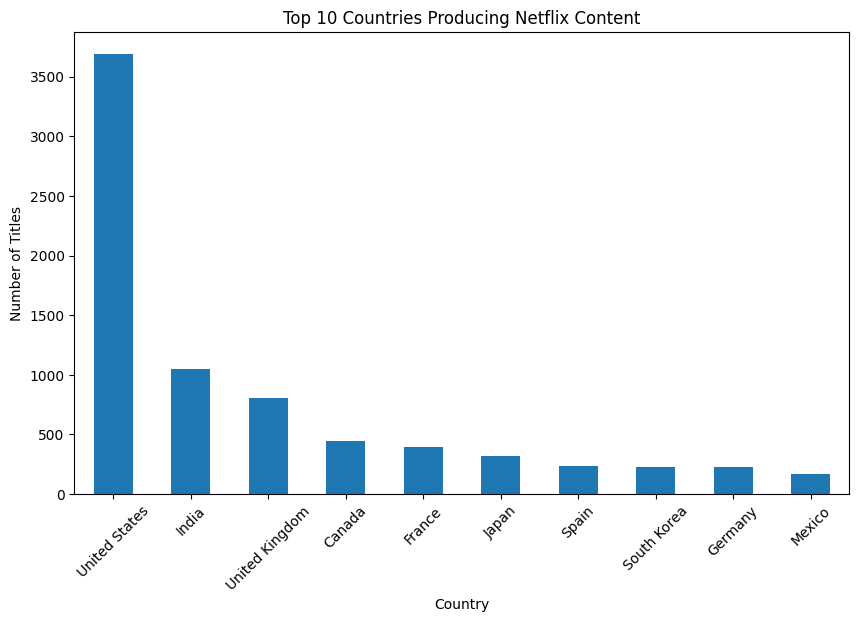

In [41]:
country_data = df["country"].dropna().str.split(", ")
all_countries = country_data.explode()
top_countries = all_countries.value_counts().head(10)

plt.figure(figsize=(10, 6))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

### Insight
The United States produces the highest number of Netflix titles, followed by other major content-producing countries.

## 6. Content Release Trend Over Time
This chart shows how the number of Netflix titles changed by release year.

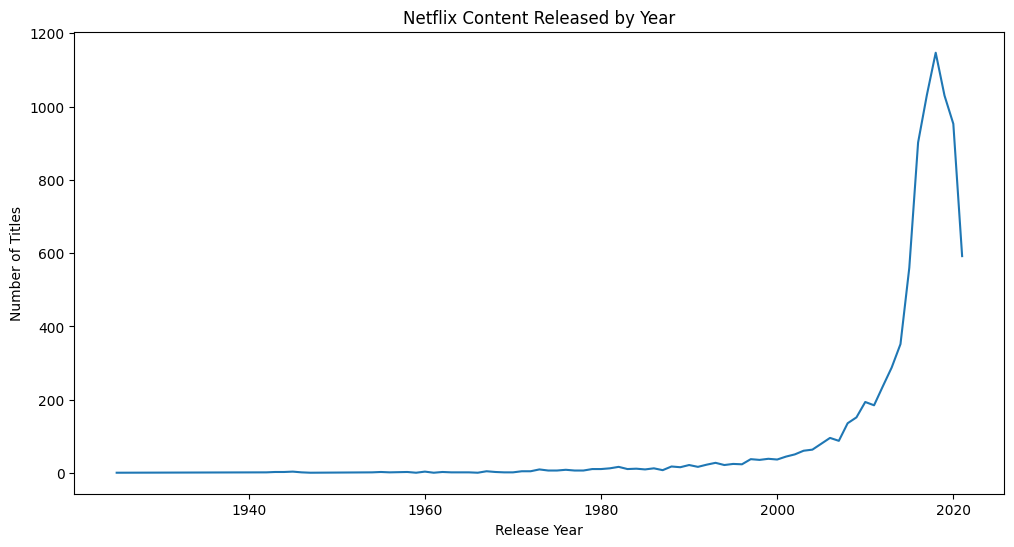

In [33]:
year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 6))
plt.plot(year_counts.index, year_counts.values)
plt.title("Netflix Content Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

### Insight
Netflix content production increased significantly after 2015.

## 7. Rating Distribution
This chart presents the most common content ratings in the dataset.

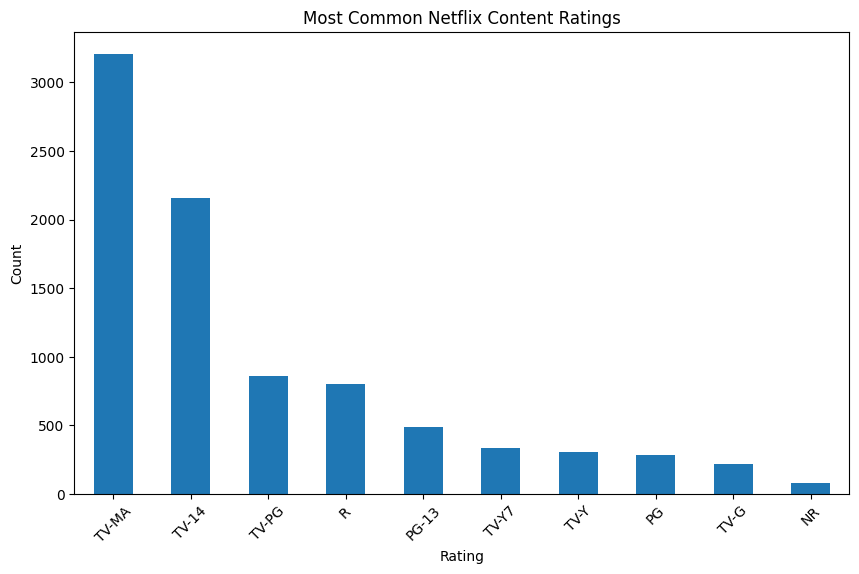

In [34]:
rating_counts = df["rating"].dropna().value_counts().head(10)

plt.figure(figsize=(10, 6))
rating_counts.plot(kind="bar")
plt.title("Most Common Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

### Insight
TV-MA and TV-14 are among the most common content ratings, showing that a large portion of Netflix content targets mature and teenage audiences.

## 8. Top 10 Directors
This section shows which directors appear most frequently in the dataset.

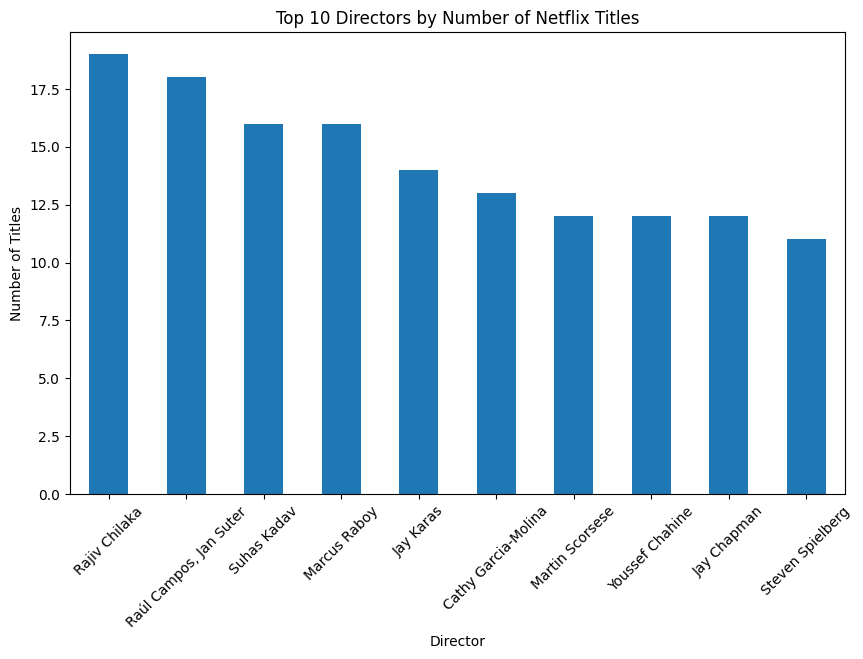

In [35]:
top_directors = df["director"].dropna().value_counts().head(10)

plt.figure(figsize=(10, 6))
top_directors.plot(kind="bar")
plt.title("Top 10 Directors by Number of Netflix Titles")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

### Insight
A small number of directors appear multiple times, which may indicate repeated collaborations or strong representation in Netflix’s catalog.

## 9. Data Cleaning Example
To demonstrate a simple cleaning step, missing values in important columns can be removed for more focused analysis.

In [42]:
df_cleaned = df.dropna(subset=["country", "rating", "director"])

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)

df_cleaned.head()

Original shape: (8807, 12)
Cleaned shape: (5750, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...


### Insight
Removing rows with missing values in key columns helps improve the reliability of focused analyses.

## 10. Conclusion

This analysis explored Netflix content using Python, Pandas, and Matplotlib.  
The dataset shows that:
- Movies are more common than TV Shows
- The United States is the leading content-producing country
- Content production increased strongly after 2015
- TV-MA and TV-14 are among the most frequent ratings

Overall, the dataset highlights both Netflix’s large catalog and its strong global content presence.